<div align="center" style="text-align:center; padding:24px 0 16px;">

<h1 style="font-size:2.4em; margin-bottom:0.2em;">Selection of Candidate Models</h1>

<h3 style="font-weight:400; margin-top:0;">easyJet Flight Delays at London Gatwick Airport</h3>

<p style="margin:12px 0 4px;"><b>Course:</b> Time Series and Forecasting - 2026/2027 - Deliverable 2</p>

<p style="margin:18px 0 4px;"><b>Authors</b></p>
<p style="margin:0; line-height:1.6;">
Joana Ferreira (up202305202)<br>
Leonor Baía (up202304808)<br>
Mariana Bissacot (up202306832)<br>
Rita Nunes (up202305232)
</p>

</div>

<br>

## Research question

> **Can we forecast the monthly average departure delay (in minutes) of easyJet flights at London Gatwick Airport?**

This notebook continues directly from **Deliverable 1**. The data preparation and exploratory analysis have already been completed, so they are not repeated here.

The purpose of this notebook is:

> **Given the characteristics already observed in the series, which time-series models are defensible candidates for the forecasting stage?**

### Scope of this notebook

The following tasks were completed in the first notebook:

- raw CAA file consolidation and schema harmonisation;
- construction of the flight-weighted monthly target;
- data-quality and temporal-coverage analysis;
- time plots and dynamics;
- trend and seasonality analysis;
- Box-Cox transformation assessment;
- STL decomposition;
- ACF-based temporal-dependence analysis;
- easyJet vs. other-airline and route-level exploratory analyses.

This notebook therefore focuses only on the **model-selection stage**.

<div align="center">

**EDA findings** → **Stationarity decision** → **ACF/PACF identification** → **Model fitting**  
↓  
**Residual diagnostics** → **COVID intervention** → **Variance check (√ / GARCH)** → **Candidate selection**

</div>


## 0. Input handed over from Deliverable 1

The input to this notebook is the **model-ready monthly series** produced in Deliverable 1.

Expected file: `easyjet_gatwick_monthly.csv`

Expected columns:
- `date`
- `average_delay_mins`
- `flights_matched`
- `number_routes`
- `number_countries`

Only a compact integrity check is performed here. Data preparation is not repeated.

In [25]:
from pathlib import Path
import warnings
import itertools

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import jarque_bera
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.tsa.seasonal import STL
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

In [26]:
# Put easyjet_gatwick_monthly.csv in the same folder as this notebook.
candidate_paths = [
    Path("easyjet_gatwick_monthly.csv"),
    Path("dados_consolidados/easyjet_gatwick_monthly.csv"),
    Path("../easyjet_gatwick_monthly.csv")
]

DATA_PATH = next((p for p in candidate_paths if p.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "easyjet_gatwick_monthly.csv was not found. Export the monthly model-ready series "
        "from Deliverable 1 and place it next to this notebook."
    )

monthly = (
    pd.read_csv(DATA_PATH, parse_dates=["date"])
      .set_index("date")
      .sort_index()
      .asfreq("MS")
)

y = monthly["average_delay_mins"].astype(float)

print(f"Input file: {DATA_PATH}")
print(f"Calendar period: {y.index.min():%b %Y} - {y.index.max():%b %Y}")
print(f"Calendar months: {len(y)}")
print(f"Valid target observations: {y.notna().sum()}")
print("Missing target months:", list(y[y.isna()].index.strftime("%Y-%m")))

Input file: dados_consolidados\easyjet_gatwick_monthly.csv
Calendar period: Jan 2001 - Jul 2026
Calendar months: 307
Valid target observations: 305
Missing target months: ['2020-04', '2020-05']


April and May 2020 have no value because easyJet operated no flights from Gatwick in those months. They stay **missing** (`NaN`): the SARIMA models used below (estimated with the Kalman filter in `SARIMAX`) can handle missing months directly, so they are never replaced by zero.

Some tests (ADF, KPSS, ACF/PACF, STL) need a complete series. For those tests only, we use a copy in which the two months are linearly interpolated (`y_diag`). This copy is never used to fit the models.

In [27]:
# Diagnostic copy for the tests only (fills April-May 2020).
y_diag = y.interpolate(method="time", limit=2)

## 1. What the EDA tells us about the model

The main findings from Deliverable 1 that matter for choosing a model:

1. **Annual seasonality** (period $S = 12$): a summer peak, a smaller December peak and a low in November. The seasonal pattern also became stronger from the mid-2010s.
2. **Short-term memory:** the ACF is 0.62 at lag 1, 0.48 at lag 2 and 0.30 at lag 3.
3. **No stable linear trend:** the level moves in long phases.
4. **Variance grows with the level:** Box-Cox $\lambda \approx 0.48$, close to a square root.
5. **COVID-19 (2020–2021):** delays collapsed to 2–5 minutes, a clear break from normal behaviour.

These points lead to **seasonal ARIMA (SARIMA)** models, plus an explicit treatment of COVID and a check of the variance.

## 2. Do we need to difference the series?

ARMA models need a **stationary** series. We use the two tests, which have opposite null hypotheses:

| Test | $H_0$ | Small p-value means |
|---|---|---|
| **ADF** | the series has a unit root (non-stationary) | the series is stationary |
| **KPSS** | the series is stationary | the series is non-stationary |

We test the original series and its differences: first ($\nabla Y_t$), seasonal ($\nabla_{12} Y_t$) and both.

In [28]:
def stationarity_tests(series, label):
    s = series.dropna()
    adf_p = adfuller(s, regression="c", autolag="AIC")[1]
    kpss_p = kpss(s, regression="c", nlags="auto")[1]
    return {"Series": label, "n": len(s),
            "ADF p-value": adf_p, "ADF says": "stationary" if adf_p < 0.05 else "unit root",
            "KPSS p-value": kpss_p, "KPSS says": "stationary" if kpss_p > 0.05 else "non-stationary"}

stationarity_table = pd.DataFrame([
    stationarity_tests(y_diag, "Original"),
    stationarity_tests(y_diag.diff(), "First difference"),
    stationarity_tests(y_diag.diff(12), "Seasonal difference (lag 12)"),
    stationarity_tests(y_diag.diff().diff(12), "First + seasonal difference"),
])
display(stationarity_table.round(4))

,Series,n,ADF p-value,ADF says,KPSS p-value,KPSS says
0,Original,307,0.002,stationary,0.100,stationary
1,First difference,306,0.000,stationary,0.100,stationary
2,Seasonal difference (lag 12),295,0.000,stationary,0.100,stationary
3,First + seasonal difference,294,0.000,stationary,0.100,stationary


*Note: statsmodels caps the KPSS p-value at 0.10, so "0.10" means "0.10 or higher".*

The lecture also uses `ndiffs` (number of first differences) and `nsdiffs` (number of seasonal differences) from R's `forecast` package. We reproduce them below:

- `ndiffs` applies the KPSS test repeatedly and counts how many differences are needed until KPSS no longer rejects stationarity.
- `nsdiffs` (default in R) uses the **seasonal strength** $F_S$ from an STL decomposition and suggests $D = 1$ when $F_S > 0.64$. We compute it with all years and excluding 2020–2021, as in Deliverable 1.

In [29]:
def ndiffs_kpss(series, alpha=0.05, max_d=2):
    s = series.dropna()
    for d in range(max_d + 1):
        if kpss(s, regression="c", nlags="auto")[1] > alpha:
            return d
        s = s.diff().dropna()
    return max_d

def seasonal_strength(series, exclude_years=()):
    fit = STL(series, period=12, seasonal=13, robust=True).fit()
    comp = pd.DataFrame({"seasonal": fit.seasonal, "remainder": fit.resid})
    comp = comp[~comp.index.year.isin(exclude_years)]
    R = comp["remainder"]
    return max(0, 1 - R.var() / (comp["seasonal"] + R).var())

fs_all = seasonal_strength(y_diag)
fs_excl = seasonal_strength(y_diag, exclude_years=(2020, 2021))

print(f"ndiffs (KPSS):                      d = {ndiffs_kpss(y_diag)}")
print(f"Seasonal strength, all years:       F_S = {fs_all:.2f} -> nsdiffs D = {int(fs_all > 0.64)}")
print(f"Seasonal strength, excl. 2020-2021: F_S = {fs_excl:.2f} -> nsdiffs D = {int(fs_excl > 0.64)}")

ndiffs (KPSS):                      d = 0
Seasonal strength, all years:       F_S = 0.51 -> nsdiffs D = 0
Seasonal strength, excl. 2020-2021: F_S = 0.66 -> nsdiffs D = 1


### Differencing decision

- **First difference ($d$):** ADF and KPSS agree that the original series is already stationary, and `ndiffs` gives $d = 0$. The level changes in phases, but it does not wander like a random walk.
- **Seasonal difference ($D$):** the answer depends on COVID. With all years, $F_S = 0.51$ and `nsdiffs` gives $D = 0$. Without 2020–2021, $F_S = 0.66$ and `nsdiffs` gives $D = 1$. The pandemic years, when there was no seasonal pattern at all, hide the seasonality of normal years. When the seasonal pattern is *"nearly constant but not quite"* ($S_t \approx S_{t-12}$), a seasonal difference with $D = 1$ is the usual solution. This matches the EDA, where the seasonal pattern repeats but its amplitude changes over time.

We therefore use **$D = 1$**. For the regular part, we keep **two families** of candidates and let the estimation decide:

- **Family A:** $d = 1,\ D = 1$, the classic SARIMA setting;
- **Family B:** $d = 0,\ D = 1$, which is what the tests point to.

We also fit one model with **no differencing at all**, a SARMA, to check whether the seasonal difference is really needed (Section 4).

## 3. Identifying the orders with the ACF and PACF

The identification rules from the lectures:

- **AR(p):** the ACF decays and the PACF cuts off after lag $p$.
- **MA(q):** the ACF cuts off after lag $q$ and the PACF decays.
- Spikes at lags 12, 24, … point to **seasonal** AR or MA terms.

We look at the ACF and PACF of the two differenced series, one for each family.

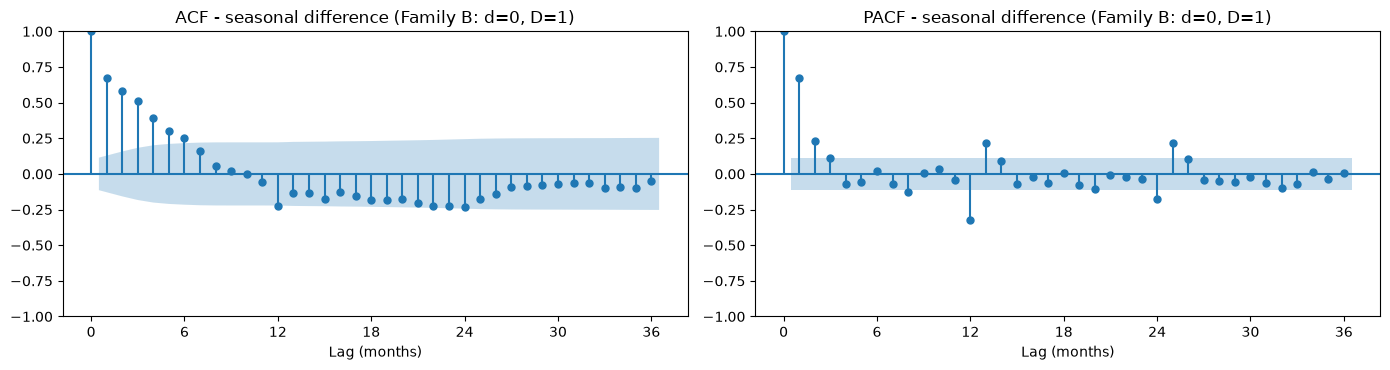

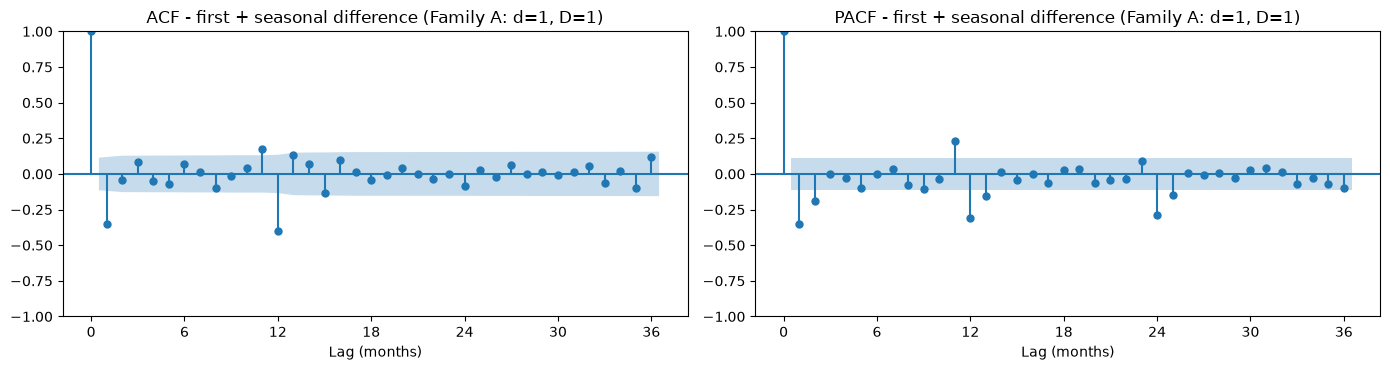

In [30]:
def plot_acf_pacf(series, title, lags=36):
    s = series.dropna()
    fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
    plot_acf(s, lags=lags, ax=axes[0])
    plot_pacf(s, lags=lags, ax=axes[1], method="ywm")
    axes[0].set_title(f"ACF - {title}")
    axes[1].set_title(f"PACF - {title}")
    for ax in axes:
        ax.set_xlabel("Lag (months)")
        ax.set_xticks(range(0, lags + 1, 6))
    plt.tight_layout()
    plt.show()

plot_acf_pacf(y_diag.diff(12), "seasonal difference (Family B: d=0, D=1)")
plot_acf_pacf(y_diag.diff().diff(12), "first + seasonal difference (Family A: d=1, D=1)")

In [31]:
def acf_pacf_values(series, label, lags=(1, 2, 3, 4, 12, 24)):
    s = series.dropna()
    a = acf(s, nlags=max(lags))
    p = pacf(s, nlags=max(lags), method="ywm")
    return pd.DataFrame({"Series": label, "Lag": lags,
                         "ACF": [a[k] for k in lags], "PACF": [p[k] for k in lags]})

display(pd.concat([
    acf_pacf_values(y_diag.diff(12), "Seasonal diff. (B)"),
    acf_pacf_values(y_diag.diff().diff(12), "First + seasonal diff. (A)"),
], ignore_index=True).round(2))
print(f"Approximate 95% band: ±{1.96 / np.sqrt(y_diag.diff(12).dropna().size):.2f}")

,Series,Lag,ACF,PACF
0,Seasonal diff. (B),1,0.670,0.670
1,Seasonal diff. (B),2,0.580,0.230
2,Seasonal diff. (B),3,0.510,0.110
3,Seasonal diff. (B),4,0.390,-0.070
4,Seasonal diff. (B),12,-0.230,-0.330
5,Seasonal diff. (B),24,-0.230,-0.180
6,First + seasonal diff. (A),1,-0.350,-0.350
7,First + seasonal diff. (A),2,-0.040,-0.190
8,First + seasonal diff. (A),3,0.080,-0.000
9,First + seasonal diff. (A),4,-0.050,-0.030


Approximate 95% band: ±0.11


### What the plots suggest

**Family B ($\nabla_{12} Y_t$):** the ACF decays gradually (0.67, 0.58, 0.51, 0.39) while the PACF has two clear spikes, at lags 1 and 2 (0.67 and 0.23), and then becomes small. This is the signature of an **AR(2)**. At lag 12 the ACF is negative (−0.23), the typical trace of a **seasonal MA(1)**. Starting candidate: **SARIMA(2,0,0)(0,1,1)$_{12}$**.

**Family A ($\nabla\nabla_{12} Y_t$):** the ACF has one spike at lag 1 (−0.35) and one at lag 12 (−0.40), with little in between, while the PACF decays. This points to a **non-seasonal MA(1)** and a **seasonal MA(1)**. Starting candidate: **SARIMA(0,1,1)(0,1,1)$_{12}$**.


The ACF and PACF are only a starting point, so we also try a few neighbouring models with one more or one less parameter.

## 4. Fitting and comparing the candidates

### How we compare models

- **AIC, AICc and BIC:** lower is better. They reward good fit but penalise extra parameters; BIC penalises them more. **AIC is only comparable between models with the same differencing ($d$, $D$)**, because differencing changes the data used in the likelihood. So we compare *within* each family.
- **Significance of the coefficients:** a coefficient that is not significant may be unnecessary.
- **Parameter redundancy:** if an AR and an MA term cancel each other, the model looks richer but is not. A clear warning sign is an **MA coefficient close to −1**, meaning an MA root on the unit circle. If the MA(1) is ≈ −1 after a first difference, the first difference is being undone, a sign of **over-differencing**.
- **Stationarity and invertibility:** all AR and MA roots must lie outside the unit circle ($|z| > 1$).
- **Ljung-Box test on the residuals:** $H_0$ = no autocorrelation. A large p-value (> 0.05) is good. The degrees of freedom are reduced by the number of estimated ARMA coefficients.

In [32]:
def fit_model(name, series, order, seasonal_order, exog=None, trend="n"):
    # Fit a SARIMA(X) model and collect the statistics used to compare candidates.
    fit = SARIMAX(series, order=order, seasonal_order=seasonal_order,
                  exog=exog, trend=trend).fit(disp=False, maxiter=1000)

    # Residuals: drop the start-up months lost to differencing and the missing months.
    burn = order[1] + 12 * seasonal_order[1] + 12
    resid = fit.resid.copy()
    resid[series.isna()] = np.nan
    resid = resid.iloc[burn:].dropna()

    n_arma = order[0] + order[2] + seasonal_order[0] + seasonal_order[2]
    lb = acorr_ljungbox(resid, lags=[12, 24], model_df=n_arma)["lb_pvalue"]

    coef = fit.params.drop("sigma2")
    row = {
        "Model": name,
        "Family": f"d={order[1]}, D={seasonal_order[1]}",
        "k": len(fit.params),
        "AIC": fit.aic, "AICc": fit.aicc, "BIC": fit.bic,
        "LB p(12)": lb.iloc[0], "LB p(24)": lb.iloc[1],
        "Max coef. p-value": fit.pvalues.drop("sigma2").max(),
        "Min |MA root|": np.min(np.abs(fit.maroots)) if len(fit.maroots) else np.nan,
        "Min |AR root|": np.min(np.abs(fit.arroots)) if len(fit.arroots) else np.nan,
    }
    return fit, resid, row

def coefficient_table(fits):
    rows = []
    for name, fit in fits.items():
        ci = fit.conf_int()
        for p in fit.params.index.drop("sigma2"):
            rows.append({"Model": name, "Parameter": p,
                         "Estimate": fit.params[p], "Std. error": fit.bse[p],
                         "p-value": fit.pvalues[p],
                         "CI 2.5%": ci.loc[p, 0], "CI 97.5%": ci.loc[p, 1]})
    return pd.DataFrame(rows)

### 4.1 Is the seasonal difference needed? A model with no differencing

Before committing to $D = 1$, we fit a stationary **SARMA(1,0,1)(1,0,1)$_{12}$** with a constant. If the seasonal AR coefficient comes out close to 1, the data are telling us that the seasonal component behaves like a seasonal random walk, i.e. that a seasonal difference is needed.

In [33]:
fit_sarma, _, row_sarma = fit_model("SARMA(1,0,1)(1,0,1)12", y, (1, 0, 1), (1, 0, 1, 12), trend="c")
display(coefficient_table({"SARMA(1,0,1)(1,0,1)12": fit_sarma}).round(3))

,Model,Parameter,Estimate,Std. error,p-value,CI 2.5%,CI 97.5%
0,"SARMA(1,0,1)(1,0,1)12",intercept,0.007,0.015,0.638,-0.022,0.036
1,"SARMA(1,0,1)(1,0,1)12",ar.L1,0.839,0.043,0.000,0.754,0.924
2,"SARMA(1,0,1)(1,0,1)12",ma.L1,-0.263,0.067,0.000,-0.394,-0.131
3,"SARMA(1,0,1)(1,0,1)12",ar.S.L12,0.997,0.005,0.000,0.987,1.008
4,"SARMA(1,0,1)(1,0,1)12",ma.S.L12,-0.935,0.065,0.000,-1.061,-0.808


The seasonal AR coefficient is **0.997**: it practically sits on the unit circle (its 95% interval includes 1). The model is effectively applying $(1 - B^{12})$ by itself, which **confirms the seasonal difference $D = 1$**. From here on, all candidates use $D = 1$.

### 4.2 SARIMA candidates without COVID treatment

Family A ($d=1$): the ACF/PACF model (0,1,1)(0,1,1) and two neighbours with more short-term AR terms.
Family B ($d=0$): the ACF/PACF model (2,0,0)(0,1,1) and two neighbours. A constant was tested in Family B but was never significant (p > 0.5), so it is left out.

In [34]:
specs = [
    # name,                       order,     seasonal order
    ("A1 SARIMA(0,1,1)(0,1,1)12", (0, 1, 1), (0, 1, 1, 12)),
    ("A2 SARIMA(1,1,1)(0,1,1)12", (1, 1, 1), (0, 1, 1, 12)),
    ("A3 SARIMA(2,1,1)(0,1,1)12", (2, 1, 1), (0, 1, 1, 12)),
    ("B1 SARIMA(1,0,0)(0,1,1)12", (1, 0, 0), (0, 1, 1, 12)),
    ("B2 SARIMA(2,0,0)(0,1,1)12", (2, 0, 0), (0, 1, 1, 12)),
    ("B3 SARIMA(1,0,1)(0,1,1)12", (1, 0, 1), (0, 1, 1, 12)),
]

fits_raw, resid_raw, rows = {}, {}, []
for name, order, sorder in specs:
    fit, resid, row = fit_model(name, y, order, sorder)
    fits_raw[name], resid_raw[name] = fit, resid
    rows.append(row)

table_raw = pd.DataFrame(rows)
display(table_raw.round(3))

,Model,Family,k,AIC,AICc,BIC,LB p(12),LB p(24),Max coef. p-value,Min |MA root|,Min |AR root|
0,"A1 SARIMA(0,1,1)(0,1,1)12","d=1, D=1",3,"1,817.004","1,817.087","1,828.055",0.000,0.001,0.000,1.008,NaN
1,"A2 SARIMA(1,1,1)(0,1,1)12","d=1, D=1",4,"1,816.737","1,816.876","1,831.472",0.015,0.007,0.000,1.005,2.164
2,"A3 SARIMA(2,1,1)(0,1,1)12","d=1, D=1",5,"1,808.147","1,808.356","1,826.565",0.004,0.007,0.424,1.000,1.206
3,"B1 SARIMA(1,0,0)(0,1,1)12","d=0, D=1",3,"1,815.564","1,815.647","1,826.625",0.022,0.015,0.000,1.001,1.386
4,"B2 SARIMA(2,0,0)(0,1,1)12","d=0, D=1",4,"1,804.439","1,804.577","1,819.187",0.007,0.010,0.000,1.005,1.212
5,"B3 SARIMA(1,0,1)(0,1,1)12","d=0, D=1",4,"1,804.822","1,804.960","1,819.570",0.009,0.009,0.000,1.006,1.177


In [35]:
display(coefficient_table(fits_raw).round(3))

,Model,Parameter,Estimate,Std. error,p-value,CI 2.5%,CI 97.5%
0,"A1 SARIMA(0,1,1)(0,1,1)12",ma.L1,-0.381,0.047,0.000,-0.473,-0.290
1,"A1 SARIMA(0,1,1)(0,1,1)12",ma.S.L12,-0.908,0.052,0.000,-1.009,-0.807
2,"A2 SARIMA(1,1,1)(0,1,1)12",ar.L1,0.462,0.088,0.000,0.290,0.634
3,"A2 SARIMA(1,1,1)(0,1,1)12",ma.L1,-0.797,0.065,0.000,-0.924,-0.670
4,"A2 SARIMA(1,1,1)(0,1,1)12",ma.S.L12,-0.937,0.061,0.000,-1.057,-0.817
5,"A3 SARIMA(2,1,1)(0,1,1)12",ar.L1,0.576,0.045,0.000,0.488,0.664
6,"A3 SARIMA(2,1,1)(0,1,1)12",ar.L2,0.210,0.056,0.000,0.101,0.320
7,"A3 SARIMA(2,1,1)(0,1,1)12",ma.L1,-0.999,0.510,0.050,-1.999,0.000
8,"A3 SARIMA(2,1,1)(0,1,1)12",ma.S.L12,-0.997,1.248,0.424,-3.443,1.448
9,"B1 SARIMA(1,0,0)(0,1,1)12",ar.L1,0.722,0.035,0.000,0.654,0.789


### Reading the results

- **Within Family A,** A3 has the lowest AICc, but its MA(1) coefficient is **−0.999**, with the MA root on the unit circle ($|z| = 1.000$), and its seasonal MA is not significant. This is the **parameter redundancy** from the ARMA lecture. An MA(1) of −1 cancels the first difference $(1 - B)$, meaning **the first difference is not needed**. A3 is therefore discarded, and it is one more piece of evidence for Family B ($d = 0$). A2 is the best valid model in Family A.
- **Within Family B,** B2 has the lowest AICc and BIC, and all its coefficients are significant. B3 is almost identical. B1 has a seasonal MA very close to −1 and a worse AICc.
- **But every model fails the Ljung-Box test** (p < 0.05): the residuals still contain structure. The next section shows where it comes from.

## 5. Residual check: where does the remaining structure come from?

If a model is adequate, its residuals should look like **white noise**. We plot the residuals of the two leading candidates, A2 and B2.

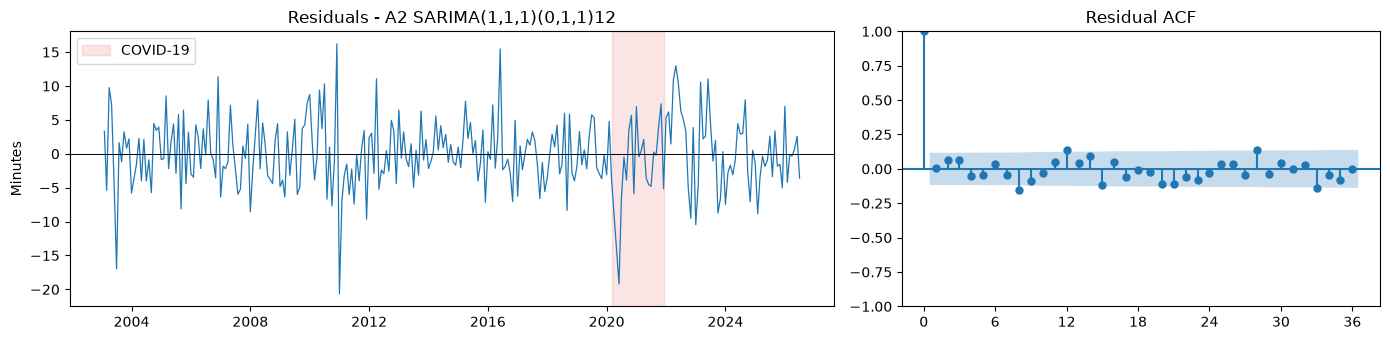

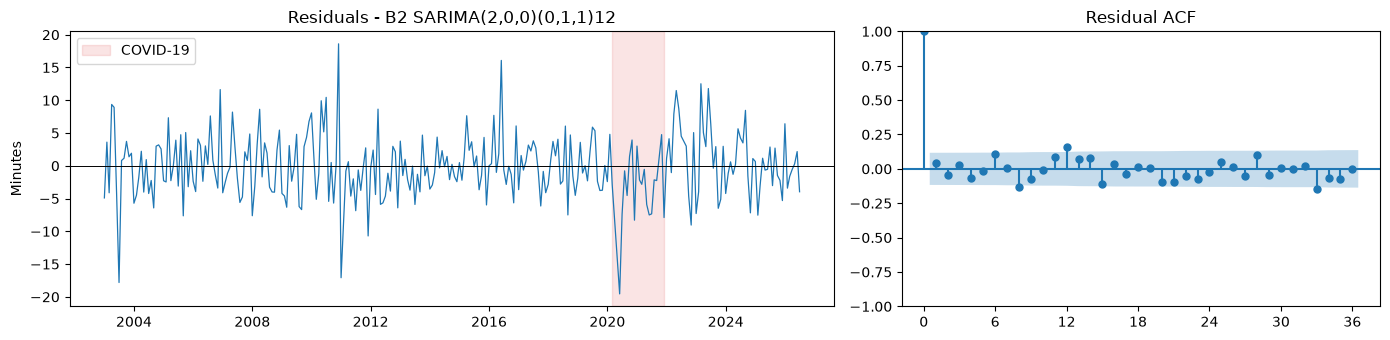

In [36]:
def plot_residuals(resid, title, ylabel="Minutes"):
    fig, axes = plt.subplots(1, 2, figsize=(14, 3.5), gridspec_kw={"width_ratios": [1.6, 1]})
    axes[0].plot(resid.index, resid, linewidth=0.9)
    axes[0].axhline(0, color="black", linewidth=0.7)
    axes[0].axvspan(pd.Timestamp("2020-03-01"), pd.Timestamp("2021-12-01"), color="tab:red", alpha=0.12, label="COVID-19")
    axes[0].set_title(f"Residuals - {title}")
    axes[0].set_ylabel(ylabel)
    axes[0].legend(loc="upper left")
    plot_acf(resid, lags=36, ax=axes[1])
    axes[1].set_title("Residual ACF")
    axes[1].set_xticks(range(0, 37, 6))
    plt.tight_layout()
    plt.show()

for name in ["A2 SARIMA(1,1,1)(0,1,1)12", "B2 SARIMA(2,0,0)(0,1,1)12"]:
    plot_residuals(resid_raw[name], name)

Several of the largest residuals fall in **2020–2022** (shaded). Without being told about the pandemic, the models expect normal summer peaks in 2020 and 2021 and badly overestimate the delays, producing large negative residuals, followed by large positive ones in the 2022 rebound. These errors come in runs rather than at random, which is part of why the Ljung-Box test fails. **COVID has to be modelled explicitly.**

## 6. How should COVID-19 be treated?

The pandemic really happened, so it should not simply be ignored, but it also should not be learned as "normal" behaviour. We compare four approaches on both leading structures (A2 and B2):

| Approach | What it does |
|---|---|
| **No treatment** | The SARIMA has to absorb the pandemic on its own, as in Section 4. |
| **One dummy** | A variable that is 1 from March 2020 to December 2021 and 0 otherwise. The model estimates by how many minutes delays shifted in that period, and learns its dynamics from the remaining months. |
| **Two dummies** | One variable for March–December 2020 (acute phase) and another for 2021 (partial recovery), in case the two phases had different effects. |
| **Masked** | The COVID months are set to missing, as if they had not been observed. |

A model with dummy variables is written SARIMAX, where the X stands for exogenous variables. The dummy is known in advance, so it is simply 0 in all future months when forecasting.

**AIC comparison:** "no treatment", "one dummy" and "two dummies" use the same data and can be compared by AICc. The **masked** model uses 20 fewer observations, so its AIC is **not comparable**; we judge it by its coefficients and residuals.

In [37]:
idx = y.index
interventions = pd.DataFrame(index=idx)
interventions["covid"] = ((idx >= "2020-03-01") & (idx <= "2021-12-01")).astype(int)
interventions["covid_2020"] = ((idx >= "2020-03-01") & (idx <= "2020-12-01")).astype(int)
interventions["covid_2021"] = ((idx >= "2021-01-01") & (idx <= "2021-12-01")).astype(int)

y_masked = y.copy()
y_masked.loc["2020-03-01":"2021-12-01"] = np.nan

display(interventions.loc["2020-01-01":"2022-02-01"].T)

date,2020-01-01,2020-02-01,2020-03-01,2020-04-01,2020-05-01,2020-06-01,2020-07-01,2020-08-01,2020-09-01,2020-10-01,2020-11-01,2020-12-01,2021-01-01,2021-02-01,2021-03-01,2021-04-01,2021-05-01,2021-06-01,2021-07-01,2021-08-01,2021-09-01,2021-10-01,2021-11-01,2021-12-01,2022-01-01,2022-02-01
covid,0,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,0
covid_2020,0,0,1,1,1,1,1,1,1,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0
covid_2021,0,0,0,0,0,0,0,0,0,0,0,0,1,1,1,1,1,1,1,1,1,1,1,1,0,0


In [38]:
structures = {
    "A2 SARIMA(1,1,1)(0,1,1)12": ((1, 1, 1), (0, 1, 1, 12)),
    "B2 SARIMA(2,0,0)(0,1,1)12": ((2, 0, 0), (0, 1, 1, 12)),
}
approaches = {
    "No treatment": dict(series=y, exog=None),
    "One dummy":    dict(series=y, exog=interventions[["covid"]]),
    "Two dummies":  dict(series=y, exog=interventions[["covid_2020", "covid_2021"]]),
    "Masked":       dict(series=y_masked, exog=None),
}

covid_rows, covid_fits = [], {}
for sname, (order, sorder) in structures.items():
    for aname, a in approaches.items():
        fit, resid, row = fit_model(f"{sname[:2]} + {aname}", a["series"], order, sorder, exog=a["exog"])
        row["Structure"], row["COVID approach"] = sname, aname
        row["Observations used"] = int(a["series"].notna().sum())
        if aname == "Masked":
            row["AIC"] = row["AICc"] = row["BIC"] = np.nan   # not comparable
        covid_rows.append(row)
        covid_fits[(sname[:2], aname)] = fit

covid_table = pd.DataFrame(covid_rows)[
    ["Structure", "COVID approach", "Observations used", "AICc", "BIC",
     "LB p(12)", "LB p(24)", "Max coef. p-value"]
]
display(covid_table.round(3))

,Structure,COVID approach,Observations used,AICc,BIC,LB p(12),LB p(24),Max coef. p-value
0,"A2 SARIMA(1,1,1)(0,1,1)12",No treatment,305,"1,816.876","1,831.472",0.015,0.007,0.000
1,"A2 SARIMA(1,1,1)(0,1,1)12",One dummy,305,"1,803.414","1,821.624",0.197,0.182,0.000
2,"A2 SARIMA(1,1,1)(0,1,1)12",Two dummies,305,"1,804.927","1,826.736",0.193,0.170,0.000
3,"A2 SARIMA(1,1,1)(0,1,1)12",Masked,285,NaN,NaN,0.086,0.165,0.000
4,"B2 SARIMA(2,0,0)(0,1,1)12",No treatment,305,"1,804.577","1,819.187",0.007,0.010,0.000
5,"B2 SARIMA(2,0,0)(0,1,1)12",One dummy,305,"1,795.383","1,813.610",0.039,0.074,0.001
6,"B2 SARIMA(2,0,0)(0,1,1)12",Two dummies,305,"1,796.654","1,818.484",0.037,0.071,0.013
7,"B2 SARIMA(2,0,0)(0,1,1)12",Masked,285,NaN,NaN,0.052,0.241,0.000


In [39]:
covid_coefs = []
for (s, a), fit in covid_fits.items():
    for p in fit.params.index.drop("sigma2"):
        covid_coefs.append({"Structure": s, "COVID approach": a, "Parameter": p,
                            "Estimate": fit.params[p], "p-value": fit.pvalues[p]})
covid_coefs = pd.DataFrame(covid_coefs)
display(
    covid_coefs.pivot_table(index=["Structure", "Parameter"], columns="COVID approach",
                            values="Estimate", sort=False).round(3)
)

COVID approach        No treatment  One dummy  Two dummies  Masked
Structure Parameter                                               
A2        ar.L1              0.462      0.492        0.494   0.343
          ma.L1             -0.797     -0.893       -0.893  -0.809
          ma.S.L12          -0.937     -0.912       -0.909  -0.819
          covid                NaN    -12.652          NaN     NaN
          covid_2020           NaN        NaN      -14.063     NaN
          covid_2021           NaN        NaN      -11.462     NaN
B2        ar.L1              0.569      0.525        0.526   0.478
          ma.S.L12          -0.938     -0.916       -0.912  -0.832
          covid                NaN    -10.457          NaN     NaN
          covid_2020           NaN        NaN      -12.303     NaN
          covid_2021           NaN        NaN       -8.968     NaN
          ar.L2              0.211      0.169        0.169   0.223

### COVID: conclusions

- **Treating COVID matters a lot.** For both structures, adding one dummy lowers the AICc by about 9–14 points, and for A2 the Ljung-Box test now passes. The COVID coefficient is large and significant: in 2020–2021 delays were about **10–13 minutes lower** than the normal pattern would predict.
- **One dummy is enough.** With two dummies, both effects are negative and of similar size, and the AICc gets slightly *worse* (by about 1.3–1.5). The extra parameter does not pay for itself.
- **Masking also works, but it changes the model more.** Its coefficients move noticeably (for example, the seasonal MA weakens from about −0.91 to about −0.82). Masking discards 20 real observations, whereas the dummy keeps them and only corrects their level. We keep masking as a robustness check, not as the main approach.

**Decision:** all final candidates include **one COVID dummy** (March 2020 – December 2021).

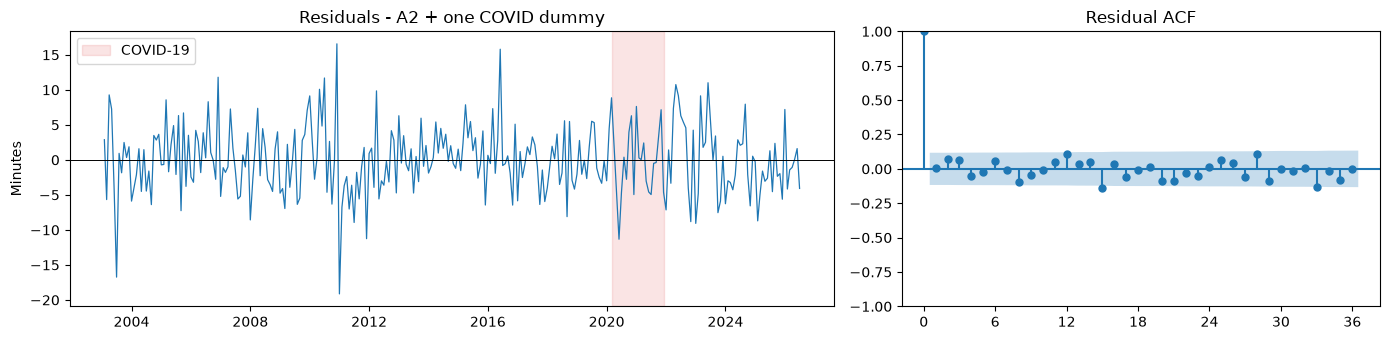

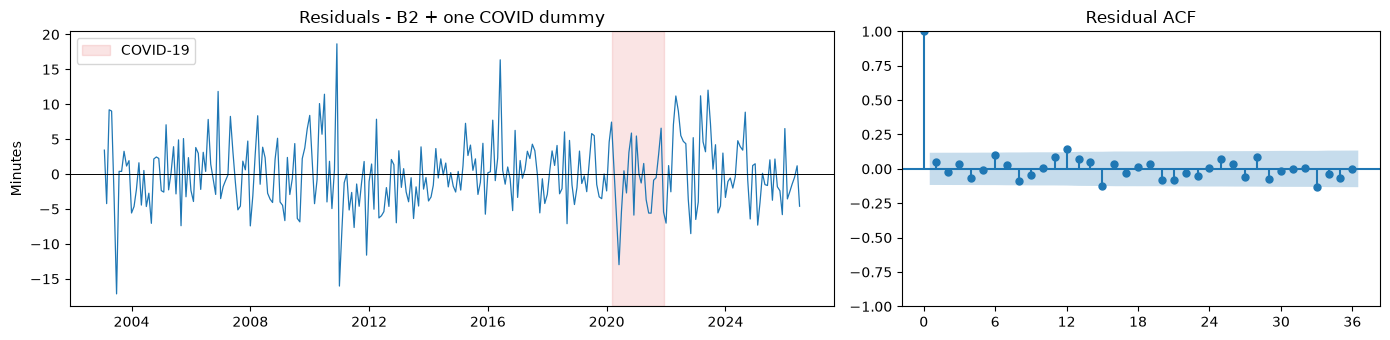

In [40]:
for s in ["A2", "B2"]:
    fit = covid_fits[(s, "One dummy")]
    resid = fit.resid.copy()
    resid[y.isna()] = np.nan
    plot_residuals(resid.iloc[25:].dropna(), f"{s} + one COVID dummy")

## 7. Variance: square-root transformation or GARCH?

The EDA showed that **high-delay years are also more volatile** (Box-Cox $\lambda \approx 0.48$). If the variance changes over time, the residuals will show **ARCH effects**: their *squares* are autocorrelated even when the residuals themselves are not. This is checked with the ACF of the squared residuals. We also use the **ARCH-LM test** ($H_0$: no ARCH effects).

There are two possible responses:
1. **Transform the series** with $\sqrt{Y_t}$, as the Box-Cox estimate suggests, and model the transformed series;
2. **Add a GARCH model** for the variance of the residuals.

We start with the simpler one, the transformation, and only consider GARCH if it is not enough.

**Comparing AIC across scales:** a model for $\sqrt{Y_t}$ has its likelihood on a different scale, so its AIC cannot be compared directly with the model in minutes. We convert it back to the original scale by adding the Jacobian of the transformation, $2\sum_t \log\!\left(2\sqrt{y_t}\right)$, which gives an AICc in "minutes" that *can* be compared with the untransformed model of the same family.

In [41]:
sqrt_y = np.sqrt(y)
X_covid = interventions[["covid"]]

def arch_checks(resid):
    return {"ARCH-LM p": het_arch(resid.values, nlags=12)[1],
            "LB p(12) squared resid.": acorr_ljungbox(resid**2, lags=[12])["lb_pvalue"].iloc[0]}

var_rows, final_fits, final_resid = [], {}, {}
for sname, (order, sorder) in structures.items():
    for scale, series in [("Minutes", y), ("Square root", sqrt_y)]:
        label = f"{sname[:2]} + COVID ({scale.lower()})"
        fit, resid, row = fit_model(label, series, order, sorder, exog=X_covid)
        aicc_minutes = row["AICc"]
        if scale == "Square root":
            jacobian = 2 * np.sum(np.log(2 * np.sqrt(y.dropna())))
            aicc_minutes = row["AICc"] + jacobian
        var_rows.append({"Model": label, "Scale": scale,
                         "AICc (minutes scale)": aicc_minutes,
                         "LB p(12)": row["LB p(12)"], "LB p(24)": row["LB p(24)"],
                         **arch_checks(resid)})
        final_fits[label], final_resid[label] = fit, resid

variance_table = pd.DataFrame(var_rows)
display(variance_table.round(3))

,Model,Scale,AICc (minutes scale),LB p(12),LB p(24),ARCH-LM p,LB p(12) squared resid.
0,A2 + COVID (minutes),Minutes,"1,803.414",0.197,0.182,0.007,0.006
1,A2 + COVID (square root),Square root,"1,778.878",0.234,0.175,0.720,0.900
2,B2 + COVID (minutes),Minutes,"1,795.383",0.039,0.074,0.007,0.016
3,B2 + COVID (square root),Square root,"1,767.397",0.082,0.115,0.818,0.911


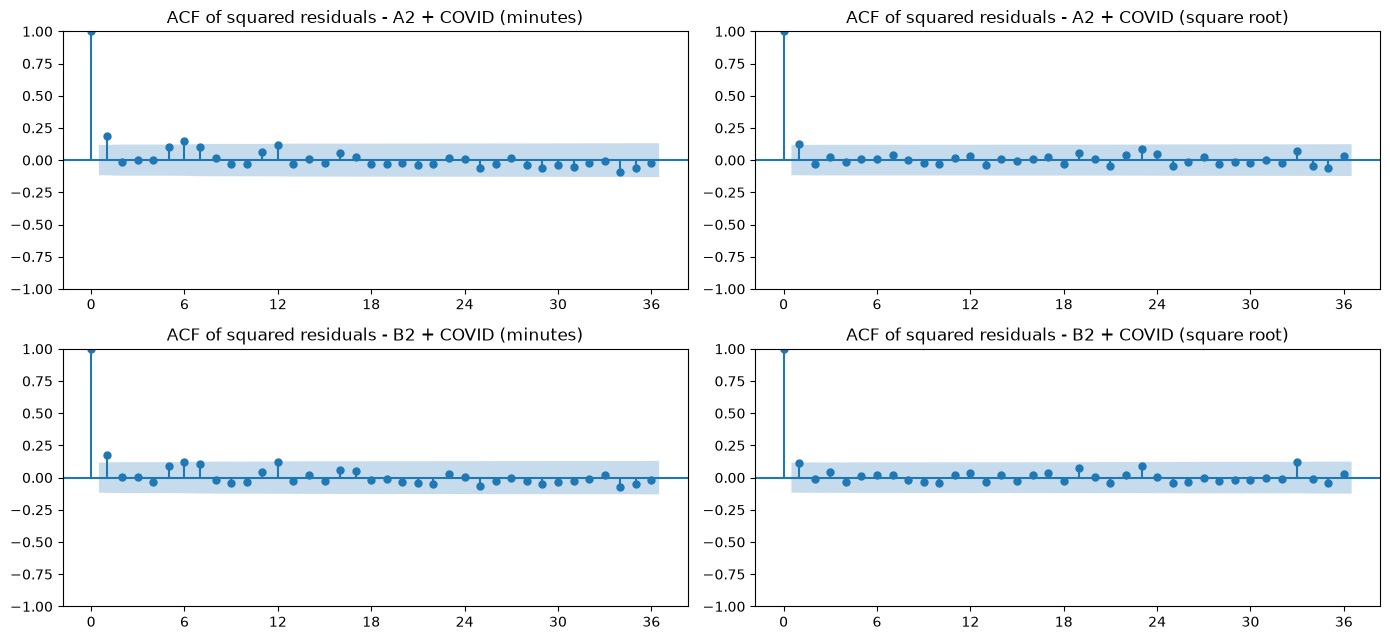

In [42]:
fig, axes = plt.subplots(2, 2, figsize=(14, 6.5))
pairs = [("A2 + COVID (minutes)", "A2 + COVID (square root)"),
         ("B2 + COVID (minutes)", "B2 + COVID (square root)")]
for row_axes, (raw_name, sqrt_name) in zip(axes, pairs):
    for ax, name in zip(row_axes, (raw_name, sqrt_name)):
        plot_acf(final_resid[name] ** 2, lags=36, ax=ax)
        ax.set_title(f"ACF of squared residuals - {name}")
        ax.set_xticks(range(0, 37, 6))
plt.tight_layout()
plt.show()

### Variance: conclusions

- **In minutes,** both models show clear ARCH effects (ARCH-LM p < 0.01): the squared residuals are autocorrelated, so the variance is not constant.
- **With the square root,** the ARCH effects disappear (ARCH-LM p > 0.7), the Ljung-Box tests are no longer rejected at the 5% level for either model, and the AICc on the minutes scale *improves* by about 25–28 points.
- **GARCH is not needed**: it models the variance of the residuals and would only be added on top of the SARIMA if ARCH effects remained, which they do not after the square-root transformation.

**Decision:** the final candidates model $\sqrt{Y_t}$. Forecasts will be squared back to minutes in Deliverable 3.

## 8. Final check of the selected candidates

Coefficients, roots and residuals of the two models carried forward.

In [43]:
selected = ["A2 + COVID (square root)", "B2 + COVID (square root)"]
display(coefficient_table({k: final_fits[k] for k in selected}).round(3))

roots = pd.DataFrame([{
    "Model": k,
    "Min |AR root|": np.min(np.abs(final_fits[k].arroots)),
    "Min |MA root|": np.min(np.abs(final_fits[k].maroots)),
} for k in selected])
roots["Stationary and invertible?"] = (roots["Min |AR root|"] > 1) & (roots["Min |MA root|"] > 1)
display(roots.round(3))

,Model,Parameter,Estimate,Std. error,p-value,CI 2.5%,CI 97.5%
0,A2 + COVID (square root),covid,-1.781,0.162,0.000,-2.097,-1.464
1,A2 + COVID (square root),ar.L1,0.485,0.072,0.000,0.344,0.626
2,A2 + COVID (square root),ma.L1,-0.881,0.040,0.000,-0.959,-0.802
3,A2 + COVID (square root),ma.S.L12,-0.912,0.045,0.000,-1.001,-0.824
4,B2 + COVID (square root),covid,-1.522,0.174,0.000,-1.864,-1.180
5,B2 + COVID (square root),ar.L1,0.538,0.049,0.000,0.441,0.634
6,B2 + COVID (square root),ar.L2,0.173,0.052,0.001,0.071,0.275
7,B2 + COVID (square root),ma.S.L12,-0.917,0.049,0.000,-1.014,-0.821


,Model,Min |AR root|,Min |MA root|,Stationary and invertible?
0,A2 + COVID (square root),2.061,1.008,True
1,B2 + COVID (square root),1.309,1.007,True


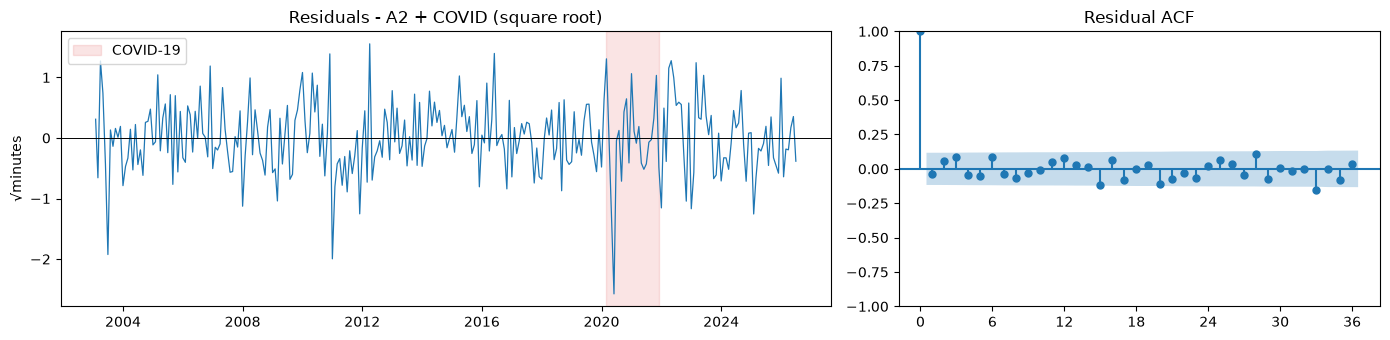

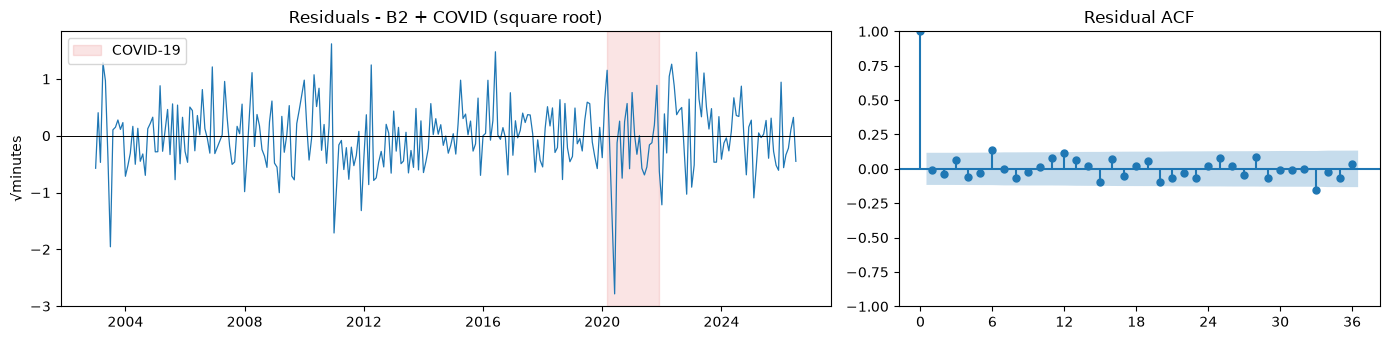

In [44]:
for k in selected:
    plot_residuals(final_resid[k], k, ylabel="√minutes")

Both models have only significant coefficients, all roots outside the unit circle, residuals without systematic autocorrelation and no remaining ARCH effects.

The residuals are now on the square-root scale ($\sqrt{\text{minutes}}$).

## 9. Candidates carried forward to Deliverable 3

| | Model | Why it is a candidate |
|---|---|---|
| **Candidate 1** | $\sqrt{Y_t}$: SARIMA(2,0,0)(0,1,1)$_{12}$ + COVID dummy | Follows directly from the tests ($d=0$, $D=1$) and the PACF (AR(2)); lowest AICc in its family. |
| **Candidate 2** | $\sqrt{Y_t}$: SARIMA(1,1,1)(0,1,1)$_{12}$ + COVID dummy | Best valid model with the classic $d=1$, $D=1$ setting; best Ljung-Box results. |
| *Reference* | SARIMA(0,1,1)(0,1,1)$_{12}$ (minutes, no COVID) | The textbook seasonal model suggested by the ACF; a reference point, not a final candidate (its residuals fail the Ljung-Box test). |
| *Benchmark* | Seasonal naïve: $\hat{Y}_t = Y_{t-12}$ | The minimum standard any model must beat. |

**Rejected, and why:**
- **SARMA without differencing:** its seasonal AR is ≈ 1, so a seasonal difference is needed.
- **SARIMA(2,1,1)(0,1,1)$_{12}$:** its MA(1) ≈ −1 is parameter redundancy, the first difference being undone.
- **Two COVID dummies:** no improvement over one.
- **Masked COVID:** discards data and distorts the coefficients.
- **GARCH:** not needed after the square-root transformation.

**Why two candidates and not one:** the two families differ in their differencing, so AIC cannot decide between them. That choice will be made in Deliverable 3 by **comparing out-of-sample forecasts** (rolling origin, 12-month horizon) against the seasonal naïve benchmark.

## 10. Export tables for the report

In [45]:
OUT_DIR = Path("resultados_d2")
OUT_DIR.mkdir(exist_ok=True)

stationarity_table.to_csv(OUT_DIR / "d2_stationarity_tests.csv", index=False)
table_raw.to_csv(OUT_DIR / "d2_candidates_no_covid.csv", index=False)
coefficient_table(fits_raw).to_csv(OUT_DIR / "d2_coefficients_no_covid.csv", index=False)
covid_table.to_csv(OUT_DIR / "d2_covid_treatments.csv", index=False)
variance_table.to_csv(OUT_DIR / "d2_variance_check.csv", index=False)
coefficient_table({k: final_fits[k] for k in selected}).to_csv(OUT_DIR / "d2_final_coefficients.csv", index=False)

for f in sorted(OUT_DIR.glob("*.csv")):
    print(f)

resultados_d2\d2_candidates_no_covid.csv
resultados_d2\d2_coefficients_no_covid.csv
resultados_d2\d2_covid_treatments.csv
resultados_d2\d2_final_coefficients.csv
resultados_d2\d2_stationarity_tests.csv
resultados_d2\d2_variance_check.csv
